In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

path = Path('september_predictions.csv')
if not path.exists():
    try:
        from google.colab import files
        print('Upload the Week 7 september_predictions.csv file.')
        uploaded = files.upload()
        if path.name not in uploaded:
            raise FileNotFoundError('Please upload september_predictions.csv and rerun this cell.')
    except ImportError:
        raise FileNotFoundError('Place september_predictions.csv beside this notebook.')

pred = pd.read_csv(path)
required = {'Actual_ClosePrice', 'Predicted_ClosePrice'}
missing = required - set(pred.columns)
if missing:
    raise ValueError(f'Missing required columns: {sorted(missing)}')
print('Loaded rows:', len(pred))
display(pred.head())

Loaded rows: 11186


,Actual_ClosePrice,Predicted_ClosePrice
0,1025000.0,1123105.40
1,1450000.0,2293508.20
2,948000.0,940733.94
3,2650000.0,1925833.20
4,2835000.0,3623651.80


In [2]:
evaluation = pred.copy()
for col in ['Actual_ClosePrice', 'Predicted_ClosePrice']:
    evaluation[col] = pd.to_numeric(evaluation[col], errors='coerce')
valid = np.isfinite(evaluation['Actual_ClosePrice']) & np.isfinite(evaluation['Predicted_ClosePrice'])
print('Rows excluded due to missing/non-finite values:', int((~valid).sum()))
evaluation = evaluation.loc[valid].copy()
if evaluation.empty:
    raise ValueError('No valid prediction rows remain.')
evaluation['Error'] = evaluation['Predicted_ClosePrice'] - evaluation['Actual_ClosePrice']
evaluation['Absolute_Error'] = evaluation['Error'].abs()
evaluation['APE_pct'] = np.where(
    evaluation['Actual_ClosePrice'] > 0,
    100 * evaluation['Absolute_Error'] / evaluation['Actual_ClosePrice'],
    np.nan
)
print('Nonpositive actual prices excluded from percentage metrics:', int((evaluation['Actual_ClosePrice'] <= 0).sum()))
display(evaluation[['Actual_ClosePrice', 'Predicted_ClosePrice', 'Absolute_Error', 'APE_pct']].head())

Rows excluded due to missing/non-finite values: 0
Nonpositive actual prices excluded from percentage metrics: 0


,Actual_ClosePrice,Predicted_ClosePrice,Absolute_Error,APE_pct
0,1025000.0,1123105.40,98105.40,9.571259
1,1450000.0,2293508.20,843508.20,58.172979
2,948000.0,940733.94,7266.06,0.766462
3,2650000.0,1925833.20,724166.80,27.327049
4,2835000.0,3623651.80,788651.80,27.818406


In [3]:
def summarize(group):
    y = group['Actual_ClosePrice'].to_numpy(dtype=float)
    p = group['Predicted_ClosePrice'].to_numpy(dtype=float)
    ape = group['APE_pct'].dropna()
    return pd.Series({
        'n_properties': len(group),
        'n_valid_pct': len(ape),
        'R2': r2_score(y, p) if len(group) >= 2 and np.var(y) > 0 else np.nan,
        'MAE_USD': mean_absolute_error(y, p),
        'RMSE_USD': np.sqrt(mean_squared_error(y, p)),
        'MAPE_pct': ape.mean() if len(ape) else np.nan,
        'MdAPE_pct': ape.median() if len(ape) else np.nan,
        'Median_AE_USD': group['Absolute_Error'].median(),
        'Bias_USD': group['Error'].mean(),
    })

overall = summarize(evaluation)
display(overall.to_frame('September 2026'))

,September 2026
n_properties,11186.000000
n_valid_pct,11186.000000
R2,0.775145
MAE_USD,252736.186439
RMSE_USD,674390.590436
MAPE_pct,21.086803
MdAPE_pct,13.622876
Median_AE_USD,123513.450000
Bias_USD,-17462.708808


In [4]:
bins = [-np.inf, 300_000, 600_000, 1_000_000, np.inf]
labels = ['Under $300k', '$300k–<$600k', '$600k–<$1M', '$1M+']
evaluation['Price_Band'] = pd.cut(
    evaluation['Actual_ClosePrice'], bins=bins, labels=labels, right=False
)
by_band = evaluation.groupby('Price_Band', observed=False).apply(
    summarize, include_groups=False
)
by_band.index.name = 'Price_Band'
display(by_band.round(2))

,n_properties,n_valid_pct,R2,MAE_USD,RMSE_USD,MAPE_pct,MdAPE_pct,Median_AE_USD,Bias_USD
Price_Band,,,,,,,,,
Under $300k,274.0,274.0,-17.04,191422.95,269943.32,128.72,60.10,148985.20,189070.37
$300k–<$600k,2265.0,2265.0,-3.59,109242.37,172573.35,24.05,16.23,76751.06,84649.81
$600k–<$1M,3832.0,3832.0,-1.92,128447.13,190872.31,16.35,11.52,90324.84,60472.53
$1M+,4815.0,4815.0,0.70,422640.44,1004702.63,17.34,13.61,224718.80,-139274.29


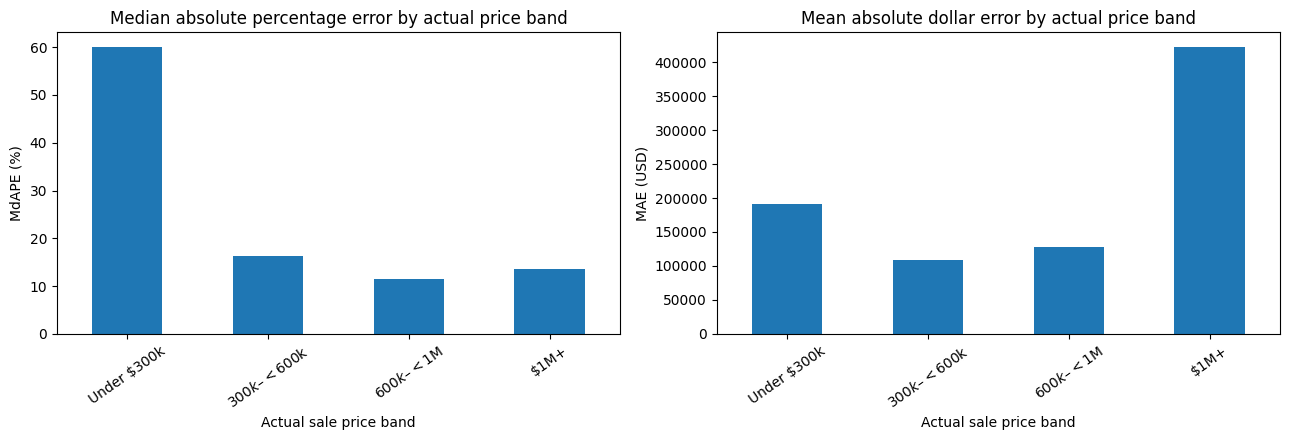

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
by_band['MdAPE_pct'].plot(kind='bar', ax=axes[0], title='Median absolute percentage error by actual price band')
axes[0].set_ylabel('MdAPE (%)')
by_band['MAE_USD'].plot(kind='bar', ax=axes[1], title='Mean absolute dollar error by actual price band')
axes[1].set_ylabel('MAE (USD)')
for ax in axes:
    ax.set_xlabel('Actual sale price band')
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

In [6]:
below_cap = evaluation.loc[evaluation['Actual_ClosePrice'] <= 17_000_000]
comparison = pd.DataFrame({
    'All valid September sales': summarize(evaluation),
    'Actual price <= $17M': summarize(below_cap) if len(below_cap) else pd.Series(dtype=float)
}).T
display(comparison.round(2))

,n_properties,n_valid_pct,R2,MAE_USD,RMSE_USD,MAPE_pct,MdAPE_pct,Median_AE_USD,Bias_USD
All valid September sales,11186.0,11186.0,0.78,252736.19,674390.59,21.09,13.62,123513.45,-17462.71
Actual price <= $17M,11174.0,11174.0,0.82,239753.51,525623.15,21.05,13.61,123343.15,-4227.36


In [7]:
summary = pd.concat([
    overall.to_frame().T.assign(Segment='Overall'),
    by_band.reset_index().rename(columns={'Price_Band':'Segment'})
], ignore_index=True)
summary = summary[['Segment', 'n_properties', 'n_valid_pct', 'R2', 'MAE_USD',
                   'RMSE_USD', 'MAPE_pct', 'MdAPE_pct', 'Median_AE_USD', 'Bias_USD']]
summary.to_csv('metrics_summary.csv', index=False, float_format='%.6f')
print('Saved metrics_summary.csv')
display(summary.round(2))
try:
    from google.colab import files
    files.download('metrics_summary.csv')
except ImportError:
    pass

Saved metrics_summary.csv


,Segment,n_properties,n_valid_pct,R2,MAE_USD,RMSE_USD,MAPE_pct,MdAPE_pct,Median_AE_USD,Bias_USD
0,Overall,11186.0,11186.0,0.78,252736.19,674390.59,21.09,13.62,123513.45,-17462.71
1,Under $300k,274.0,274.0,-17.04,191422.95,269943.32,128.72,60.10,148985.20,189070.37
2,$300k–<$600k,2265.0,2265.0,-3.59,109242.37,172573.35,24.05,16.23,76751.06,84649.81
3,$600k–<$1M,3832.0,3832.0,-1.92,128447.13,190872.31,16.35,11.52,90324.84,60472.53
4,$1M+,4815.0,4815.0,0.70,422640.44,1004702.63,17.34,13.61,224718.80,-139274.29


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The Week 8 evaluation demonstrates that XGBoost prediction accuracy varies substantially across residential property price segments. The model performs best in relative percentage terms for properties priced between $600,000 and $1 million, with a median absolute percentage error of 11.52%. Lower-priced properties exhibit substantial overprediction, while luxury properties tend to be underpredicted. These findings highlight opportunities for improving model calibration and prediction accuracy across market segments.